In [0]:



volume_path = "/Volumes/workspace/default/cmapss_data"

display(dbutils.fs.ls(volume_path))


path,name,size,modificationTime
dbfs:/Volumes/workspace/default/cmapss_data/Damage Propagation Modeling.pdf,Damage Propagation Modeling.pdf,434158,1788872548000
dbfs:/Volumes/workspace/default/cmapss_data/RUL_FD001.txt,RUL_FD001.txt,429,1788872538000
dbfs:/Volumes/workspace/default/cmapss_data/RUL_FD002.txt,RUL_FD002.txt,1110,1788872537000
dbfs:/Volumes/workspace/default/cmapss_data/RUL_FD003.txt,RUL_FD003.txt,428,1788872537000
dbfs:/Volumes/workspace/default/cmapss_data/RUL_FD004.txt,RUL_FD004.txt,1084,1788872538000
dbfs:/Volumes/workspace/default/cmapss_data/readme.txt,readme.txt,2442,1788872537000
dbfs:/Volumes/workspace/default/cmapss_data/test_FD001.txt,test_FD001.txt,2228855,1788872603000
dbfs:/Volumes/workspace/default/cmapss_data/test_FD002.txt,test_FD002.txt,5734587,1788872669000
dbfs:/Volumes/workspace/default/cmapss_data/test_FD003.txt,test_FD003.txt,2826651,1788872616000
dbfs:/Volumes/workspace/default/cmapss_data/test_FD004.txt,test_FD004.txt,6957759,1788872753000


In [0]:

from pyspark.sql import functions as F

base_path = "/Volumes/workspace/default/cmapss_data"

# Define the 26 expected columns
columns = (
    ["unit_number", "cycle"]
    + [f"op_setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

def load_cmapss_file(file_path):
    # Read each row as a single text line
    lines = spark.read.text(file_path)

    # Split on one or more whitespace characters
    split_df = lines.select(
        F.split(F.trim(F.col("value")), r"\s+").alias("values")
    )

    # Extract exactly the 26 values and convert them to numbers
    result = split_df.select(
        *[
            F.col("values")[i].cast("double").alias(columns[i])
            for i in range(26)
        ]
    )

    return result

# Load the original FD001 files
train_raw = load_cmapss_file(
    f"{base_path}/train_FD001.txt"
)

test_raw = load_cmapss_file(
    f"{base_path}/test_FD001.txt"
)

print("Training rows:", train_raw.count())
print("Training columns:", len(train_raw.columns))

print("Testing rows:", test_raw.count())
print("Testing columns:", len(test_raw.columns))

display(train_raw.limit(5))


Training rows: 20631
Training columns: 26
Testing rows: 13096
Testing columns: 26


unit_number,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
1.0,1.0,-7.0E-4,-4.0E-4,100.0,518.67,641.82,1589.7,1400.6,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392.0,2388.0,100.0,39.06,23.419
1.0,2.0,0.0019,-3.0E-4,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392.0,2388.0,100.0,39.0,23.4236
1.0,3.0,-0.0043,3.0E-4,100.0,518.67,642.35,1587.99,1404.2,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390.0,2388.0,100.0,38.95,23.3442
1.0,4.0,7.0E-4,0.0,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392.0,2388.0,100.0,38.88,23.3739
1.0,5.0,-0.0019,-2.0E-4,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.0,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.8,8.4294,0.03,393.0,2388.0,100.0,38.9,23.4044


In [0]:

from pyspark.sql import functions as F

# Find the final observed cycle for each training engine
engine_life = (
    train_raw
    .groupBy("unit_number")
    .agg(F.max("cycle").alias("max_cycle"))
)

# Attach each engine's final cycle and calculate RUL
train_labeled = (
    train_raw
    .join(engine_life, on="unit_number", how="left")
    .withColumn("RUL", F.col("max_cycle") - F.col("cycle"))
)

# Verify the results
print("Training rows:", train_labeled.count())
print("Number of engines:", engine_life.count())

display(
    train_labeled
    .filter(F.col("unit_number") == 1)
    .orderBy("cycle")
    .select("unit_number", "cycle", "max_cycle", "RUL")
    .limit(10)
)


Training rows: 20631
Number of engines: 100


unit_number,cycle,max_cycle,RUL
1.0,1.0,192.0,191.0
1.0,2.0,192.0,190.0
1.0,3.0,192.0,189.0
1.0,4.0,192.0,188.0
1.0,5.0,192.0,187.0
1.0,6.0,192.0,186.0
1.0,7.0,192.0,185.0
1.0,8.0,192.0,184.0
1.0,9.0,192.0,183.0
1.0,10.0,192.0,182.0


In [0]:

# Check RUL values for engine 1
display(
    train_labeled
    .filter(F.col("unit_number") == 1)
    .orderBy("cycle")
    .select("unit_number", "cycle", "max_cycle", "RUL")
    .limit(10)
)

# Check overall RUL statistics
display(
    train_labeled.select("RUL").summary(
        "count", "min", "max", "mean"
    )
)

# Check for missing values
display(
    train_labeled.select(
        F.sum(
            F.when(F.col("RUL").isNull(), 1).otherwise(0)
        ).alias("missing_RUL")
    )
)


unit_number,cycle,max_cycle,RUL
1.0,1.0,192.0,191.0
1.0,2.0,192.0,190.0
1.0,3.0,192.0,189.0
1.0,4.0,192.0,188.0
1.0,5.0,192.0,187.0
1.0,6.0,192.0,186.0
1.0,7.0,192.0,185.0
1.0,8.0,192.0,184.0
1.0,9.0,192.0,183.0
1.0,10.0,192.0,182.0


summary,RUL
count,20631
min,0.0
max,361.0
mean,107.80786195530997


missing_RUL
0


In [0]:

# Create a separate schema for this project
spark.sql("""
CREATE SCHEMA IF NOT EXISTS workspace.predictive_maintenance_rul
""")

# Verify the schema exists
spark.sql("""
SHOW SCHEMAS IN workspace
""").show(truncate=False)


+--------------------------+
|databaseName              |
+--------------------------+
|bronze                    |
|default                   |
|gold                      |
|information_schema        |
|manufacturing_qc          |
|predictive_maintenance_rul|
|silver                    |
|transportation_analytics  |
+--------------------------+



In [0]:

# Save the labeled training dataset as a Delta table
(
    train_labeled.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable(
        "workspace.predictive_maintenance_rul.train_labeled"
    )
)

# Verify the saved table
saved_train = spark.table(
    "workspace.predictive_maintenance_rul.train_labeled"
)

print("Saved training rows:", saved_train.count())
display(saved_train.limit(5))


Saved training rows: 20631


unit_number,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,max_cycle,RUL
1.0,1.0,-7.0E-4,-4.0E-4,100.0,518.67,641.82,1589.7,1400.6,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392.0,2388.0,100.0,39.06,23.419,192.0,191.0
1.0,2.0,0.0019,-3.0E-4,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392.0,2388.0,100.0,39.0,23.4236,192.0,190.0
1.0,3.0,-0.0043,3.0E-4,100.0,518.67,642.35,1587.99,1404.2,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390.0,2388.0,100.0,38.95,23.3442,192.0,189.0
1.0,4.0,7.0E-4,0.0,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392.0,2388.0,100.0,38.88,23.3739,192.0,188.0
1.0,5.0,-0.0019,-2.0E-4,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.0,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.8,8.4294,0.03,393.0,2388.0,100.0,38.9,23.4044,192.0,187.0


In [0]:

# Save the raw FD001 test data as a separate Delta table
(
    test_raw.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable(
        "workspace.predictive_maintenance_rul.test_raw"
    )
)

# Load the official RUL labels
rul_path = "/Volumes/workspace/default/cmapss_data/RUL_FD001.txt"

rul_labels = (
    spark.read.text(rul_path)
    .select(F.trim(F.col("value")).cast("int").alias("RUL"))
    .withColumn(
        "unit_number",
        F.row_number().over(
            __import__("pyspark").sql.Window.orderBy(F.monotonically_increasing_id())
        )
    )
    .select("unit_number", "RUL")
)

# Save official test RUL labels
(
    rul_labels.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable(
        "workspace.predictive_maintenance_rul.test_rul_labels"
    )
)

print("Test sensor rows:", test_raw.count())
print("Test RUL label rows:", rul_labels.count())

display(rul_labels.orderBy("unit_number").limit(10))


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


Test sensor rows: 13096
Test RUL label rows: 100


unit_number,RUL
1,112
2,98
3,69
4,82
5,91
6,93
7,91
8,95
9,111
10,96


In [0]:

from pyspark.sql import functions as F

rul_path = "/Volumes/workspace/default/cmapss_data/RUL_FD001.txt"

# Read the small file as one complete text record
rul_labels = (
    spark.read
    .option("wholetext", "true")
    .text(rul_path)
    .select(
        F.posexplode(
            F.split(F.trim(F.col("value")), r"\r?\n")
        ).alias("position", "rul_value")
    )
    .select(
        (F.col("position") + 1).alias("unit_number"),
        F.trim(F.col("rul_value")).cast("int").alias("RUL")
    )
)

# Replace the labels table with correctly ordered labels
(
    rul_labels.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable(
        "workspace.predictive_maintenance_rul.test_rul_labels"
    )
)

print("Test RUL label rows:", rul_labels.count())
display(rul_labels.orderBy("unit_number").limit(10))


Test RUL label rows: 100


unit_number,RUL
1,69
1,91
1,112
1,82
1,93
1,98
1,111
1,95
1,91
1,96


In [0]:

schema = "workspace.predictive_maintenance_rul"

for table in ["train_labeled", "test_raw", "test_rul_labels"]:
    df = spark.table(f"{schema}.{table}")
    print(f"{table}: {df.count()} rows")


train_labeled: 20631 rows
test_raw: 13096 rows
test_rul_labels: 100 rows


In [0]:

from pyspark.sql import functions as F
from pyspark.sql.window import Window

schema = "workspace.predictive_maintenance_rul"

# Load the saved training data
train_labeled = spark.table(f"{schema}.train_labeled")

# Define a window for each engine's recent operating cycles
w = (
    Window.partitionBy("unit_number")
    .orderBy("cycle")
)

w3 = w.rowsBetween(-2, 0)

# Select sensor columns for feature engineering
sensor_cols = [f"sensor_{i}" for i in range(1, 22)]

# Create rolling averages and cycle-to-cycle changes
features = train_labeled

for c in sensor_cols:
    features = (
        features
        .withColumn(
            f"{c}_rolling_avg_3",
            F.avg(F.col(c)).over(w3)
        )
        .withColumn(
            f"{c}_change",
            F.col(c) - F.lag(F.col(c), 1).over(w)
        )
    )

# The first cycle has no previous reading, so use zero for its change
for c in sensor_cols:
    features = features.withColumn(
        f"{c}_change",
        F.coalesce(F.col(f"{c}_change"), F.lit(0.0))
    )

print("Original training rows:", train_labeled.count())
print("Engineered feature columns:", len(features.columns))

display(
    features.select(
        "unit_number", "cycle", "RUL",
        "sensor_2", "sensor_2_rolling_avg_3",
        "sensor_2_change"
    ).filter(F.col("unit_number") == 1).limit(10)
)


Original training rows: 20631
Engineered feature columns: 70


unit_number,cycle,RUL,sensor_2,sensor_2_rolling_avg_3,sensor_2_change
1.0,1.0,191.0,641.82,641.82,0.0
1.0,2.0,190.0,642.15,641.985,0.32999999999992724
1.0,3.0,189.0,642.35,642.1066666666667,0.20000000000004547
1.0,4.0,188.0,642.35,642.2833333333333,0.0
1.0,5.0,187.0,642.37,642.3566666666667,0.01999999999998181
1.0,6.0,186.0,642.1,642.2733333333334,-0.2699999999999818
1.0,7.0,185.0,642.48,642.3166666666667,0.37999999999999545
1.0,8.0,184.0,642.56,642.38,0.07999999999992724
1.0,9.0,183.0,642.12,642.3866666666667,-0.4399999999999409
1.0,10.0,182.0,641.71,642.13,-0.40999999999996817


In [0]:

schema = "workspace.predictive_maintenance_rul"

# Save engineered features as a separate Delta table
(
    features.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable(f"{schema}.train_features")
)

# Verify the saved table
saved_features = spark.table(f"{schema}.train_features")

print("Saved rows:", saved_features.count())
print("Saved columns:", len(saved_features.columns))

display(saved_features.limit(5))


Saved rows: 20631
Saved columns: 70


unit_number,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,max_cycle,RUL,sensor_1_rolling_avg_3,sensor_1_change,sensor_2_rolling_avg_3,sensor_2_change,sensor_3_rolling_avg_3,sensor_3_change,sensor_4_rolling_avg_3,sensor_4_change,sensor_5_rolling_avg_3,sensor_5_change,sensor_6_rolling_avg_3,sensor_6_change,sensor_7_rolling_avg_3,sensor_7_change,sensor_8_rolling_avg_3,sensor_8_change,sensor_9_rolling_avg_3,sensor_9_change,sensor_10_rolling_avg_3,sensor_10_change,sensor_11_rolling_avg_3,sensor_11_change,sensor_12_rolling_avg_3,sensor_12_change,sensor_13_rolling_avg_3,sensor_13_change,sensor_14_rolling_avg_3,sensor_14_change,sensor_15_rolling_avg_3,sensor_15_change,sensor_16_rolling_avg_3,sensor_16_change,sensor_17_rolling_avg_3,sensor_17_change,sensor_18_rolling_avg_3,sensor_18_change,sensor_19_rolling_avg_3,sensor_19_change,sensor_20_rolling_avg_3,sensor_20_change,sensor_21_rolling_avg_3,sensor_21_change
1.0,1.0,-7.0E-4,-4.0E-4,100.0,518.67,641.82,1589.7,1400.6,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392.0,2388.0,100.0,39.06,23.419,192.0,191.0,518.67,0.0,641.82,0.0,1589.7,0.0,1400.6,0.0,14.62,0.0,21.61,0.0,554.36,0.0,2388.06,0.0,9046.19,0.0,1.3,0.0,47.47,0.0,521.66,0.0,2388.02,0.0,8138.62,0.0,8.4195,0.0,0.03,0.0,392.0,0.0,2388.0,0.0,100.0,0.0,39.06,0.0,23.419,0.0
1.0,2.0,0.0019,-3.0E-4,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392.0,2388.0,100.0,39.0,23.4236,192.0,190.0,518.67,0.0,641.985,0.32999999999992724,1590.76,2.119999999999891,1401.87,2.540000000000191,14.62,0.0,21.61,0.0,554.0550000000001,-0.6100000000000136,2388.05,-0.01999999999998181,9045.130000000001,-2.1200000000008004,1.3,0.0,47.480000000000004,0.020000000000003126,521.97,0.6200000000000045,2388.045,0.0500000000001819,8135.055,-7.130000000000109,8.425650000000001,0.012300000000001532,0.03,0.0,392.0,0.0,2388.0,0.0,100.0,0.0,39.03,-0.060000000000002274,23.421300000000002,0.0045999999999999375
1.0,3.0,-0.0043,3.0E-4,100.0,518.67,642.35,1587.99,1404.2,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390.0,2388.0,100.0,38.95,23.3442,192.0,189.0,518.67,0.0,642.1066666666667,0.20000000000004547,1589.8366666666668,-3.8299999999999272,1402.6466666666665,1.0599999999999454,14.62,0.0,21.61,0.0,554.1233333333333,0.5099999999999909,2388.06,0.03999999999996362,9047.733333333335,8.8700000000008,1.3,0.0,47.410000000000004,-0.21999999999999886,522.12,0.13999999999998636,2388.0400000000004,-0.03999999999996362,8134.446666666667,1.7399999999997817,8.423033333333334,-0.014000000000001123,0.03,0.0,391.3333333333333,-2.0,2388.0,0.0,100.0,0.0,39.00333333333334,-0.04999999999999716,23.3956,-0.07939999999999969
1.0,4.0,7.0E-4,0.0,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392.0,2388.0,100.0,38.88,23.3739,192.0,188.0,518.67,0.0,642.2833333333333,0.0,1587.5333333333335,-5.2000000000000455,1403.07,-2.3300000000001546,14.62,0.0,21.61,0.0,554.1533333333333,0.19000000000005457,2388.0766666666664,0.03000000000020009,9048.83,-3.460000000000946,1.3,0.0,47.296666666666674,-0.14000000000000057,522.52,0.44000000000005457,2388.06,0.04999999999972715,8132.849999999999,0.6000000000003638,8.405933333333335,-0.049599999999999866,0.03,0.0,391.3333333333333,2.0,2388.0,0.0,100.0,0.0,38.943333333333335,-0.07000000000000028,23.380566666666667,0.029699999999998283
1.0,5.0,-0.0019,-2.0E-4,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.0,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.8,8.4294,0.03,393.0,2388.0,100.0,38.9,23.4044,192.0,187.0,518.67,0.0,642.3566666666667,0.01999999999998181,1584.543333333333,0.05999999999994543,1404.0966666666666,4.350000000000136,14.62,0.0,21.61,0.0,554.2366666666667,-

In [0]:

from pyspark.sql import functions as F

schema = "workspace.predictive_maintenance_rul"

features = spark.table(f"{schema}.train_features")

# Get the distinct engine IDs
engine_ids = [
    row["unit_number"]
    for row in features.select("unit_number")
    .distinct()
    .orderBy("unit_number")
    .collect()
]

# Use 80 engines for training and 20 for validation
train_engines = engine_ids[:80]
validation_engines = engine_ids[80:]

train_df = features.filter(
    F.col("unit_number").isin(train_engines)
)

validation_df = features.filter(
    F.col("unit_number").isin(validation_engines)
)

print("Training engines:", len(train_engines))
print("Validation engines:", len(validation_engines))
print("Training rows:", train_df.count())
print("Validation rows:", validation_df.count())

print("Training RUL range:")
train_df.select(
    F.min("RUL").alias("min_RUL"),
    F.max("RUL").alias("max_RUL")
).show()

print("Validation RUL range:")
validation_df.select(
    F.min("RUL").alias("min_RUL"),
    F.max("RUL").alias("max_RUL")
).show()


Training engines: 80
Validation engines: 20
Training rows: 16138
Validation rows: 4493
Training RUL range:
+-------+-------+
|min_RUL|max_RUL|
+-------+-------+
|    0.0|  361.0|
+-------+-------+

Validation RUL range:
+-------+-------+
|min_RUL|max_RUL|
+-------+-------+
|    0.0|  340.0|
+-------+-------+



In [0]:

from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.sql import functions as F

# Exclude identifiers, target, and columns that reveal each engine's final cycle
exclude_cols = {"unit_number", "cycle", "max_cycle", "RUL"}

feature_cols = [
    c for c in train_df.columns
    if c not in exclude_cols
]

# Assemble the sensor and engineered features
assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features",
    handleInvalid="skip"
)

# Create the regression model
rf = RandomForestRegressor(
    featuresCol="features",
    labelCol="RUL",
    predictionCol="prediction",
    numTrees=50,
    maxDepth=8,
    seed=42
)

# Build and train the pipeline
pipeline = Pipeline(stages=[assembler, rf])

rul_model = pipeline.fit(train_df)

print("Model training completed!")
print("Number of input features:", len(feature_cols))

# Generate validation predictions
validation_predictions = rul_model.transform(validation_df)

display(
    validation_predictions.select(
        "unit_number", "cycle", "RUL", "prediction"
    ).limit(10)
)


Model training completed!
Number of input features: 66


unit_number,cycle,RUL,prediction
81.0,1.0,239.0,147.73820024845355
81.0,2.0,238.0,136.73048672633143
81.0,3.0,237.0,141.0030433391638
81.0,4.0,236.0,133.0948516202286
81.0,5.0,235.0,147.45871509884583
81.0,6.0,234.0,147.1935464853341
81.0,7.0,233.0,155.34193263059814
81.0,8.0,232.0,144.41659818553362
81.0,9.0,231.0,141.6790638584757
81.0,10.0,230.0,143.44567824156945


In [0]:

from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.sql import functions as F

# Evaluate predictions against the true RUL values
mae_evaluator = RegressionEvaluator(
    labelCol="RUL",
    predictionCol="prediction",
    metricName="mae"
)

rmse_evaluator = RegressionEvaluator(
    labelCol="RUL",
    predictionCol="prediction",
    metricName="rmse"
)

r2_evaluator = RegressionEvaluator(
    labelCol="RUL",
    predictionCol="prediction",
    metricName="r2"
)

mae = mae_evaluator.evaluate(validation_predictions)
rmse = rmse_evaluator.evaluate(validation_predictions)
r2 = r2_evaluator.evaluate(validation_predictions)

print(f"MAE:  {mae:.2f} cycles")
print(f"RMSE: {rmse:.2f} cycles")
print(f"R²:   {r2:.4f}")

# Inspect prediction errors
error_df = validation_predictions.withColumn(
    "absolute_error",
    F.abs(F.col("RUL") - F.col("prediction"))
)

display(
    error_df.select(
        "unit_number", "cycle", "RUL",
        "prediction", "absolute_error"
    ).orderBy(F.desc("absolute_error")).limit(10)
)


MAE:  35.71 cycles
RMSE: 50.45 cycles
R²:   0.5761


unit_number,cycle,RUL,prediction,absolute_error
92.0,3.0,338.0,148.99196782904232,189.00803217095768
92.0,1.0,340.0,152.03278857531396,187.96721142468604
92.0,6.0,335.0,148.99148241951116,186.00851758048884
92.0,9.0,332.0,147.39535096386925,184.60464903613075
92.0,8.0,333.0,148.48061637385572,184.51938362614428
92.0,4.0,337.0,152.6231842705662,184.3768157294338
92.0,2.0,339.0,154.74540153919187,184.25459846080813
92.0,5.0,336.0,151.78124451925837,184.21875548074163
92.0,7.0,334.0,150.7343833781015,183.2656166218985
96.0,2.0,334.0,152.6293182063353,181.3706817936647


In [0]:

import os

# Temporary storage for MLflow Spark model artifacts
os.environ["MLFLOW_DFS_TMP"] = (
    "/Volumes/workspace/default/cmapss_data/mlflow_tmp"
)

# Verify the temporary path is accessible
dbutils.fs.mkdirs(
    "dbfs:/Volumes/workspace/default/cmapss_data/mlflow_tmp"
)

print("MLflow temporary storage configured.")


MLflow temporary storage configured.


In [0]:

import mlflow
import mlflow.spark

mlflow.set_experiment("/Shared/PredictiveMaintenance_RUL")

with mlflow.start_run(run_name="RandomForest_RUL_Baseline"):

    mlflow.log_param("model_type", "RandomForestRegressor")
    mlflow.log_param("num_trees", 50)
    mlflow.log_param("max_depth", 8)
    mlflow.log_param("feature_count", len(feature_cols))
    mlflow.log_param("training_engines", 80)
    mlflow.log_param("validation_engines", 20)

    mlflow.log_metric("MAE_cycles", float(mae))
    mlflow.log_metric("RMSE_cycles", float(rmse))
    mlflow.log_metric("R2", float(r2))

    mlflow.spark.log_model(
        spark_model=rul_model,
        artifact_path="rul_random_forest",
        dfs_tmpdir="/Volumes/workspace/default/cmapss_data/mlflow_tmp"
    )

    print("Run ID:", mlflow.active_run().info.run_id)

print("MLflow logging completed.")


2026/10/24 14:07:20 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /local_disk0/user_tmp_data/spark-2dc444ed-a458-4983-b879-ad/tmpionzkenq/model, flavor: spark). Fall back to return ['pyspark==4.3.0']. Set logging level to DEBUG to see the full traceback. 
2026/10/24 14:07:20 INFO mlflow.models.model: Model logged without a signature. Signatures are required for Databricks UC model registry as they validate model inputs and denote the expected schema of model outputs. Please set `input_example` parameter when logging the model to auto infer the model signature. To manually set the signature, please visit https://www.mlflow.org/docs/3.12.0/ml/model/signatures.html for instructions on setting signature on models.


Run ID: dc0fc47ca7aa4f3d81a948b37f93a786
MLflow logging completed.


In [0]:
import mlflow

experiment = mlflow.get_experiment_by_name(
    "/Shared/PredictiveMaintenance_RUL"
)

if experiment is None:
    print("Experiment not found.")
else:
    print("Experiment ID:", experiment.experiment_id)
    print("Experiment name:", experiment.name)

    runs = mlflow.search_runs(
        experiment_ids=[experiment.experiment_id],
        max_results=10
    )

    display(runs[[
        "run_id",
        "status",
        "metrics.MAE_cycles",
        "metrics.RMSE_cycles",
        "metrics.R2"
    ]])

Experiment ID: 689870285592579
Experiment name: /Shared/PredictiveMaintenance_RUL


run_id,status,metrics.MAE_cycles,metrics.RMSE_cycles,metrics.R2
dc0fc47ca7aa4f3d81a948b37f93a786,FINISHED,35.70972301272819,50.45323884731136,0.5761076214186515
2bf0457e162c41e6acf761ddcbdc400a,FAILED,35.70972301272819,50.45323884731136,0.5761076214186515


In [0]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

# Load the separate project's test table
test_raw = spark.table(
    "workspace.predictive_maintenance_rul.test_raw"
)

# Define time-series windows for each engine
w = Window.partitionBy("unit_number").orderBy("cycle")
w3 = w.rowsBetween(-2, 0)

sensor_cols = [f"sensor_{i}" for i in range(1, 22)]

test_features = test_raw

# Add rolling averages and cycle-to-cycle changes
for c in sensor_cols:
    test_features = (
        test_features
        .withColumn(
            f"{c}_rolling_avg_3",
            F.avg(F.col(c)).over(w3)
        )
        .withColumn(
            f"{c}_change",
            F.col(c) - F.lag(F.col(c), 1).over(w)
        )
    )

# Set the first cycle's change to zero for each engine
for c in sensor_cols:
    test_features = test_features.withColumn(
        f"{c}_change",
        F.coalesce(F.col(f"{c}_change"), F.lit(0.0))
    )

print("Test rows:", test_features.count())
print("Test feature columns:", len(test_features.columns))

display(test_features.limit(5))

Test rows: 13096
Test feature columns: 68


unit_number,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,sensor_1_rolling_avg_3,sensor_1_change,sensor_2_rolling_avg_3,sensor_2_change,sensor_3_rolling_avg_3,sensor_3_change,sensor_4_rolling_avg_3,sensor_4_change,sensor_5_rolling_avg_3,sensor_5_change,sensor_6_rolling_avg_3,sensor_6_change,sensor_7_rolling_avg_3,sensor_7_change,sensor_8_rolling_avg_3,sensor_8_change,sensor_9_rolling_avg_3,sensor_9_change,sensor_10_rolling_avg_3,sensor_10_change,sensor_11_rolling_avg_3,sensor_11_change,sensor_12_rolling_avg_3,sensor_12_change,sensor_13_rolling_avg_3,sensor_13_change,sensor_14_rolling_avg_3,sensor_14_change,sensor_15_rolling_avg_3,sensor_15_change,sensor_16_rolling_avg_3,sensor_16_change,sensor_17_rolling_avg_3,sensor_17_change,sensor_18_rolling_avg_3,sensor_18_change,sensor_19_rolling_avg_3,sensor_19_change,sensor_20_rolling_avg_3,sensor_20_change,sensor_21_rolling_avg_3,sensor_21_change
1.0,1.0,0.0023,3.0E-4,100.0,518.67,643.02,1585.29,1398.21,14.62,21.61,553.9,2388.04,9050.17,1.3,47.2,521.72,2388.03,8125.55,8.4052,0.03,392.0,2388.0,100.0,38.86,23.3735,518.67,0.0,643.02,0.0,1585.29,0.0,1398.21,0.0,14.62,0.0,21.61,0.0,553.9,0.0,2388.04,0.0,9050.17,0.0,1.3,0.0,47.2,0.0,521.72,0.0,2388.03,0.0,8125.55,0.0,8.4052,0.0,0.03,0.0,392.0,0.0,2388.0,0.0,100.0,0.0,38.86,0.0,23.3735,0.0
1.0,2.0,-0.0027,-3.0E-4,100.0,518.67,641.71,1588.45,1395.42,14.62,21.61,554.85,2388.01,9054.42,1.3,47.5,522.16,2388.06,8139.62,8.3803,0.03,393.0,2388.0,100.0,39.02,23.3916,518.67,0.0,642.365,-1.3099999999999454,1586.87,3.160000000000082,1396.815,-2.7899999999999636,14.62,0.0,21.61,0.0,554.375,0.9500000000000455,2388.025,-0.02999999999974534,9052.295,4.25,1.3,0.0,47.35,0.29999999999999716,521.94,0.4399999999999409,2388.045,0.02999999999974534,8132.585,14.069999999999709,8.39275,-0.02490000000000059,0.03,0.0,392.5,1.0,2388.0,0.0,100.0,0.0,38.94,0.1600000000000037,23.382550000000002,0.01810000000000045
1.0,3.0,3.0E-4,1.0E-4,100.0,518.67,642.46,1586.94,1401.34,14.62,21.61,554.11,2388.05,9056.96,1.3,47.5,521.97,2388.03,8130.1,8.4441,0.03,393.0,2388.0,100.0,39.08,23.4166,518.67,0.0,642.3966666666666,0.75,1586.8933333333334,-1.509999999999991,1398.3233333333335,5.919999999999845,14.62,0.0,21.61,0.0,554.2866666666667,-0.7400000000000091,2388.0333333333333,0.03999999999996362,9053.85,2.539999999999054,1.3,0.0,47.4,0.0,521.95,-0.18999999999994088,2388.0400000000004,-0.02999999999974534,8131.756666666667,-9.519999999999527,8.409866666666666,0.06380000000000052,0.03,0.0,392.6666666666667,0.0,2388.0,0.0,100.0,0.0,38.986666666666665,0.05999999999999517,23.393900000000002,0.02499999999999858
1.0,4.0,0.0042,0.0,100.0,518.67,642.44,1584.12,1406.42,14.62,21.61,554.07,2388.03,9045.29,1.3,47.28,521.38,2388.05,8132.9,8.3917,0.03,391.0,2388.0,100.0,39.0,23.3737,518.67,0.0,642.2033333333334,-0.01999999999998181,1586.5033333333333,-2.8200000000001637,1401.0600000000002,5.080000000000155,14.62,0.0,21.61,0.0,554.3433333333334,-0.03999999999996362,2388.03,-0.01999999999998181,9052.223333333333,-11.669999999998254,1.3,0.0,47.42666666666667,-0.21999999999999886,521.8366666666667,-0.5900000000000318,2388.0466666666666,0.01999999999998181,8134.206666666668,2.7999999999992724,8.405366666666668,-0.052400000000000446,0.03,0.0,392.3333333333333,-2.0,2388.0,0.0,100.0,0.0,39.03333333333333,-0.0799999999999983,23.393966666666667,-0.042899999999999494
1.0,5.0,0.0014,0.0,100.0,518.67,642.51,1587.19,1401.92,14.62,21.61,554.16,2388.01,9044.55,1.3,47.31,522.15,2388.03,8129.54,8.4031,0.03,390.0,2388.0,100.0,38.99,23.413,518.67,0.0,642.47,0.06999999999993634,1586.0833333333333,3.0700000000001637,1403.2266666666667,-4.5,14.62,0.0,21.61,0.0,554.1133333333333,0.08999999999991815,2388.03,-0.01999999999998181,9048.933333333332,-0.7400000000016007,1.3,0.0,47.36333333333334,0.030000000000001137,521.8333333333334

In [0]:
test_features.write \
    .format("delta") \
    .mode("overwrite") \
    .saveAsTable(
        "workspace.predictive_maintenance_rul.test_features"
    )

print("Test features saved successfully!")

spark.sql("""
    SELECT COUNT(*) AS total_rows
    FROM workspace.predictive_maintenance_rul.test_features
""").show()

Test features saved successfully!
+----------+
|total_rows|
+----------+
|     13096|
+----------+



In [0]:
from pyspark.sql import functions as F

# Load the saved test features
test_features = spark.table(
    "workspace.predictive_maintenance_rul.test_features"
)

# Generate predictions using the trained model
test_predictions = rul_model.transform(test_features)

# Keep predictions non-negative
test_predictions = test_predictions.withColumn(
    "predicted_RUL",
    F.greatest(F.col("prediction"), F.lit(0.0))
)

print("Total prediction rows:", test_predictions.count())

display(
    test_predictions.select(
        "unit_number",
        "cycle",
        "predicted_RUL"
    ).orderBy("unit_number", "cycle").limit(10)
)

Total prediction rows: 13096


unit_number,cycle,predicted_RUL
1.0,1.0,152.3636779396219
1.0,2.0,151.67915131348843
1.0,3.0,150.6906417301601
1.0,4.0,150.84334882827167
1.0,5.0,153.98149344699138
1.0,6.0,152.33780087799892
1.0,7.0,155.83699907337675
1.0,8.0,153.44197128392904
1.0,9.0,150.52374415796453
1.0,10.0,150.39055821886322


In [0]:
from pyspark.sql import functions as F
from pyspark.ml.evaluation import RegressionEvaluator

# Find the last observed cycle for each test engine
last_cycles = (
    test_features
    .groupBy("unit_number")
    .agg(F.max("cycle").alias("last_cycle"))
)

# Keep predictions from each engine's last observed cycle
final_predictions = (
    test_predictions
    .join(last_cycles, on="unit_number")
    .filter(F.col("cycle") == F.col("last_cycle"))
    .select(
        "unit_number",
        F.col("predicted_RUL").alias("predicted_RUL")
    )
)

# Load NASA's official test RUL labels
official_labels = spark.table(
    "workspace.predictive_maintenance_rul.test_rul_labels"
)

# Compare predictions with official labels
evaluation_df = (
    final_predictions
    .join(official_labels, on="unit_number", how="inner")
    .withColumn(
        "absolute_error",
        F.abs(F.col("RUL") - F.col("predicted_RUL"))
    )
    .withColumn(
        "squared_error",
        F.pow(F.col("RUL") - F.col("predicted_RUL"), 2)
    )
)

# Calculate evaluation metrics
metrics = evaluation_df.agg(
    F.avg("absolute_error").alias("MAE_cycles"),
    F.sqrt(F.avg("squared_error")).alias("RMSE_cycles"),
    F.count("*").alias("engines_evaluated")
)

display(metrics)

# Inspect predictions against official labels
display(
    evaluation_df
    .select("unit_number", "RUL", "predicted_RUL", "absolute_error")
    .orderBy("unit_number")
)

MAE_cycles,RMSE_cycles,engines_evaluated
75.2197473558812,85.93532447301618,100


unit_number,RUL,predicted_RUL,absolute_error
1.0,20,150.73974735588104,130.73974735588104
1.0,117,150.73974735588104,33.739747355881036
1.0,59,150.73974735588104,91.73974735588104
1.0,82,150.73974735588104,68.73974735588104
1.0,137,150.73974735588104,13.739747355881036
1.0,128,150.73974735588104,22.739747355881036
1.0,55,150.73974735588104,95.73974735588104
1.0,85,150.73974735588104,65.73974735588104
1.0,20,150.73974735588104,130.73974735588104
1.0,38,150.73974735588104,112.73974735588104


In [0]:
print("Official labels: rows and distinct engines")

spark.table(
    "workspace.predictive_maintenance_rul.test_rul_labels"
).agg(
    F.count("*").alias("rows"),
    F.countDistinct("unit_number").alias("distinct_engines")
).show()

print("Final predictions: rows and distinct engines")

final_predictions.agg(
    F.count("*").alias("rows"),
    F.countDistinct("unit_number").alias("distinct_engines")
).show()

print("Official labels sample")
display(
    spark.table(
        "workspace.predictive_maintenance_rul.test_rul_labels"
    ).orderBy("unit_number").limit(10)
)

Official labels: rows and distinct engines
+----+----------------+
|rows|distinct_engines|
+----+----------------+
| 100|               1|
+----+----------------+

Final predictions: rows and distinct engines
+----+----------------+
|rows|distinct_engines|
+----+----------------+
| 100|             100|
+----+----------------+

Official labels sample


unit_number,RUL
1,111
1,93
1,91
1,95
1,98
1,91
1,112
1,82
1,69
1,96


In [0]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window
rul_path = "/Volumes/workspace/default/cmapss_data/RUL_FD001.txt"

rul_labels = (
    spark.read.text(rul_path)
    .withColumn(
        "unit_number",
        F.row_number().over(
            Window.orderBy(F.monotonically_increasing_id())
        )
    )
    .select(
        F.col("unit_number").cast("int"),
        F.trim(F.col("value")).cast("int").alias("RUL")
    )
)

display(rul_labels.orderBy("unit_number").limit(10))

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


unit_number,RUL
1,112
2,98
3,69
4,82
5,91
6,93
7,91
8,95
9,111
10,96


In [0]:
rul_labels.write \
    .format("delta") \
    .mode("overwrite") \
    .saveAsTable(
        "workspace.predictive_maintenance_rul.test_rul_labels"
    )

# Verify the saved labels
saved_labels = spark.table(
    "workspace.predictive_maintenance_rul.test_rul_labels"
)

saved_labels.agg(
    F.count("*").alias("rows"),
    F.countDistinct("unit_number").alias("distinct_engines")
).show()

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


+----+----------------+
|rows|distinct_engines|
+----+----------------+
| 100|             100|
+----+----------------+



In [0]:
from pyspark.sql import functions as F

# Get the last observed cycle for each engine
last_cycles = (
    test_features
    .groupBy("unit_number")
    .agg(F.max("cycle").alias("last_cycle"))
)

# Select one prediction per engine
final_predictions = (
    test_predictions
    .join(last_cycles, on="unit_number")
    .filter(F.col("cycle") == F.col("last_cycle"))
    .select(
        "unit_number",
        F.col("predicted_RUL").alias("predicted_RUL")
    )
)

# Load the corrected official labels
official_labels = spark.table(
    "workspace.predictive_maintenance_rul.test_rul_labels"
)

# Compare predictions and official labels
evaluation_df = (
    final_predictions
    .join(official_labels, on="unit_number", how="inner")
    .withColumn(
        "absolute_error",
        F.abs(F.col("RUL") - F.col("predicted_RUL"))
    )
    .withColumn(
        "squared_error",
        F.pow(F.col("RUL") - F.col("predicted_RUL"), 2)
    )
)

# Calculate metrics
display(
    evaluation_df.agg(
        F.avg("absolute_error").alias("Test_MAE_cycles"),
        F.sqrt(F.avg("squared_error")).alias("Test_RMSE_cycles"),
        F.count("*").alias("Engines_evaluated"),
        F.countDistinct("unit_number").alias("Distinct_engines")
    )
)

# Inspect the first ten engines
display(
    evaluation_df
    .select("unit_number", "RUL", "predicted_RUL", "absolute_error")
    .orderBy("unit_number")
    .limit(10)
)

Test_MAE_cycles,Test_RMSE_cycles,Engines_evaluated,Distinct_engines
20.69724419980667,28.3703560279563,100,100


unit_number,RUL,predicted_RUL,absolute_error
1.0,112,150.73974735588104,38.739747355881036
2.0,98,141.24084840175277,43.24084840175277
3.0,69,57.39489663217542,11.605103367824583
4.0,82,108.70212708925236,26.702127089252357
5.0,91,116.70589749508645,25.705897495086447
6.0,93,137.8292192016432,44.82921920164321
7.0,91,112.79117414120427,21.791174141204266
8.0,95,119.3888359501291,24.388835950129106
9.0,111,136.8817435604274,25.881743560427395
10.0,96,128.99967283729856,32.99967283729856


In [0]:
(
    evaluation_df
    .select(
        "unit_number",
        "RUL",
        "predicted_RUL",
        "absolute_error"
    )
    .write
    .format("delta")
    .mode("overwrite")
    .saveAsTable(
        "workspace.predictive_maintenance_rul.test_evaluation"
    )
)

print("Test evaluation saved successfully.")

display(
    spark.table(
        "workspace.predictive_maintenance_rul.test_evaluation"
    ).orderBy("unit_number").limit(10)
)

Test evaluation saved successfully.


unit_number,RUL,predicted_RUL,absolute_error
1.0,112,150.73974735588104,38.739747355881036
2.0,98,141.24084840175277,43.24084840175277
3.0,69,57.39489663217542,11.605103367824583
4.0,82,108.70212708925236,26.702127089252357
5.0,91,116.70589749508645,25.705897495086447
6.0,93,137.8292192016432,44.82921920164321
7.0,91,112.79117414120427,21.791174141204266
8.0,95,119.3888359501291,24.388835950129106
9.0,111,136.8817435604274,25.881743560427395
10.0,96,128.99967283729856,32.99967283729856


In [0]:
%pip install shap

Looking in indexes: [REDACTED]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 547.3/547.3 kB 16.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [shap]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import shap

print("SHAP version:", shap.__version__)
print("SHAP is ready for model explainability.")

SHAP version: 0.54.1
SHAP is ready for model explainability.


In [0]:
import pandas as pd

# Use the same feature columns used during training
print("Number of model features:", len(feature_cols))

# Select a small sample from the test dataset
shap_sample_spark = (
    test_features
    .select(*feature_cols)
    .limit(100)
)

# Convert only these 100 rows to pandas
shap_sample = shap_sample_spark.toPandas()

print("Sample shape:", shap_sample.shape)
display(shap_sample.head())

Number of model features: 66
Sample shape: (100, 66)


op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,sensor_1_rolling_avg_3,sensor_1_change,sensor_2_rolling_avg_3,sensor_2_change,sensor_3_rolling_avg_3,sensor_3_change,sensor_4_rolling_avg_3,sensor_4_change,sensor_5_rolling_avg_3,sensor_5_change,sensor_6_rolling_avg_3,sensor_6_change,sensor_7_rolling_avg_3,sensor_7_change,sensor_8_rolling_avg_3,sensor_8_change,sensor_9_rolling_avg_3,sensor_9_change,sensor_10_rolling_avg_3,sensor_10_change,sensor_11_rolling_avg_3,sensor_11_change,sensor_12_rolling_avg_3,sensor_12_change,sensor_13_rolling_avg_3,sensor_13_change,sensor_14_rolling_avg_3,sensor_14_change,sensor_15_rolling_avg_3,sensor_15_change,sensor_16_rolling_avg_3,sensor_16_change,sensor_17_rolling_avg_3,sensor_17_change,sensor_18_rolling_avg_3,sensor_18_change,sensor_19_rolling_avg_3,sensor_19_change,sensor_20_rolling_avg_3,sensor_20_change,sensor_21_rolling_avg_3,sensor_21_change
0.0023,3.0E-4,100.0,518.67,643.02,1585.29,1398.21,14.62,21.61,553.9,2388.04,9050.17,1.3,47.2,521.72,2388.03,8125.55,8.4052,0.03,392.0,2388.0,100.0,38.86,23.3735,518.67,0.0,643.02,0.0,1585.29,0.0,1398.21,0.0,14.62,0.0,21.61,0.0,553.9,0.0,2388.04,0.0,9050.17,0.0,1.3,0.0,47.2,0.0,521.72,0.0,2388.03,0.0,8125.55,0.0,8.4052,0.0,0.03,0.0,392.0,0.0,2388.0,0.0,100.0,0.0,38.86,0.0,23.3735,0.0
-0.0027,-3.0E-4,100.0,518.67,641.71,1588.45,1395.42,14.62,21.61,554.85,2388.01,9054.42,1.3,47.5,522.16,2388.06,8139.62,8.3803,0.03,393.0,2388.0,100.0,39.02,23.3916,518.67,0.0,642.365,-1.3099999999999454,1586.87,3.160000000000082,1396.815,-2.7899999999999636,14.62,0.0,21.61,0.0,554.375,0.9500000000000455,2388.025,-0.02999999999974534,9052.295,4.25,1.3,0.0,47.35,0.29999999999999716,521.94,0.4399999999999409,2388.045,0.02999999999974534,8132.585,14.069999999999709,8.39275,-0.02490000000000059,0.03,0.0,392.5,1.0,2388.0,0.0,100.0,0.0,38.94,0.1600000000000037,23.382550000000002,0.01810000000000045
3.0E-4,1.0E-4,100.0,518.67,642.46,1586.94,1401.34,14.62,21.61,554.11,2388.05,9056.96,1.3,47.5,521.97,2388.03,8130.1,8.4441,0.03,393.0,2388.0,100.0,39.08,23.4166,518.67,0.0,642.3966666666666,0.75,1586.8933333333334,-1.509999999999991,1398.3233333333335,5.919999999999845,14.62,0.0,21.61,0.0,554.2866666666667,-0.7400000000000091,2388.0333333333333,0.03999999999996362,9053.85,2.539999999999054,1.3,0.0,47.4,0.0,521.95,-0.18999999999994088,2388.0400000000004,-0.02999999999974534,8131.756666666667,-9.519999999999527,8.409866666666666,0.06380000000000052,0.03,0.0,392.6666666666667,0.0,2388.0,0.0,100.0,0.0,38.986666666666665,0.05999999999999517,23.393900000000002,0.02499999999999858
0.0042,0.0,100.0,518.67,642.44,1584.12,1406.42,14.62,21.61,554.07,2388.03,9045.29,1.3,47.28,521.38,2388.05,8132.9,8.3917,0.03,391.0,2388.0,100.0,39.0,23.3737,518.67,0.0,642.2033333333334,-0.01999999999998181,1586.5033333333333,-2.8200000000001637,1401.0600000000002,5.080000000000155,14.62,0.0,21.61,0.0,554.3433333333334,-0.03999999999996362,2388.03,-0.01999999999998181,9052.223333333333,-11.669999999998254,1.3,0.0,47.42666666666667,-0.21999999999999886,521.8366666666667,-0.5900000000000318,2388.0466666666666,0.01999999999998181,8134.206666666668,2.7999999999992724,8.405366666666668,-0.052400000000000446,0.03,0.0,392.3333333333333,-2.0,2388.0,0.0,100.0,0.0,39.03333333333333,-0.0799999999999983,23.393966666666667,-0.042899999999999494
0.0014,0.0,100.0,518.67,642.51,1587.19,1401.92,14.62,21.61,554.16,2388.01,9044.55,1.3,47.31,522.15,2388.03,8129.54,8.4031,0.03,390.0,2388.0,100.0,38.99,23.413,518.67,0.0,642.47,0.06999999999993634,1586.0833333333333,3.0700000000001637,1403.2266666666667,-4.5,14.62,0.0,21.61,0.0,554.1133333333333,0.08999999999991815,2388.03,-0.01999999999998181,9048.933333333332,-0.7400000000016007,1.3,0.0,47.36333333333334,0.030000000000001137,521.8333333333334,0.7699999999999818,2388.036666666667,-0.01999999999998181

In [0]:
import shap
import numpy as np
import pandas as pd

# Extract the Random Forest model from the trained pipeline
rf_model = rul_model.stages[-1]

# Get the feature importance values from Spark ML
importances = rf_model.featureImportances.toArray()

# Create a feature-importance table
shap_importance = pd.DataFrame({
    "feature": feature_cols,
    "importance": importances
})

shap_importance = shap_importance.sort_values(
    "importance", ascending=False
)

display(shap_importance.head(15))

feature,importance
sensor_4_rolling_avg_3,0.2835508809111034
sensor_11_rolling_avg_3,0.18576811898547116
sensor_21_rolling_avg_3,0.10326090690766958
sensor_15_rolling_avg_3,0.08426140161854516
sensor_9_rolling_avg_3,0.07399666423126366
sensor_20_rolling_avg_3,0.06631657673786333
sensor_12_rolling_avg_3,0.038042233764888266
sensor_7_rolling_avg_3,0.03586376089548393
sensor_14_rolling_avg_3,0.025376555969998327
sensor_9,0.023509874780928162


In [0]:
import numpy as np
import pandas as pd

def predict_rul_for_shap(data):
    # SHAP supplies a NumPy array; restore the model's feature names
    input_pdf = pd.DataFrame(data, columns=feature_cols)

    # Convert to Spark and run the existing trained pipeline
    input_spark = spark.createDataFrame(input_pdf)
    predictions = rul_model.transform(input_spark)

    # Return predictions as a NumPy array
    return (
        predictions
        .select("prediction")
        .toPandas()["prediction"]
        .to_numpy()
    )

# Test on only 3 rows
test_input = shap_sample.iloc[:3].copy()
test_output = predict_rul_for_shap(test_input.to_numpy())

print("Test predictions:", test_output)
print("Number of predictions:", len(test_output))

Test predictions: [152.36367794 151.67915131 150.69064173]
Number of predictions: 3


In [0]:
import shap
import numpy as np

# Small background dataset and one engine to explain
background = shap_sample.iloc[:5].to_numpy()
engine_to_explain = shap_sample.iloc[10:11].to_numpy()

# Explain how the features affect this prediction
explainer = shap.KernelExplainer(
    predict_rul_for_shap,
    background
)

shap_values = explainer.shap_values(
    engine_to_explain,
    nsamples=20
)

print("SHAP calculation completed.")
print("SHAP values shape:", np.array(shap_values).shape)

  0%|          | 0/1 [00:00<?, ?it/s]

SHAP calculation completed.
SHAP values shape: (1, 66)


/databricks/python/lib/python3.12/site-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 9 iterations, i.e. alpha=5.892e-02, with an active set of 8 regressors, and the smallest cholesky pivot element being 5.960e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(


feature,shap_value,absolute_shap
sensor_20,3.86936349467934,3.86936349467934
sensor_8_change,-1.9167445327092054,1.9167445327092054
sensor_8,-1.7721801036617466,1.7721801036617466
sensor_9,-1.613011013237742,1.613011013237742
sensor_17_change,1.2380649145088156,1.2380649145088156
sensor_2_change,1.1002894845114386,1.1002894845114386
sensor_9_rolling_avg_3,-0.7808929481488027,0.7808929481488027
sensor_21_change,0.2201910280283524,0.2201910280283524
sensor_7_rolling_avg_3,0.0034146337249865047,0.0034146337249865047
sensor_18_rolling_avg_3,0.0,0.0


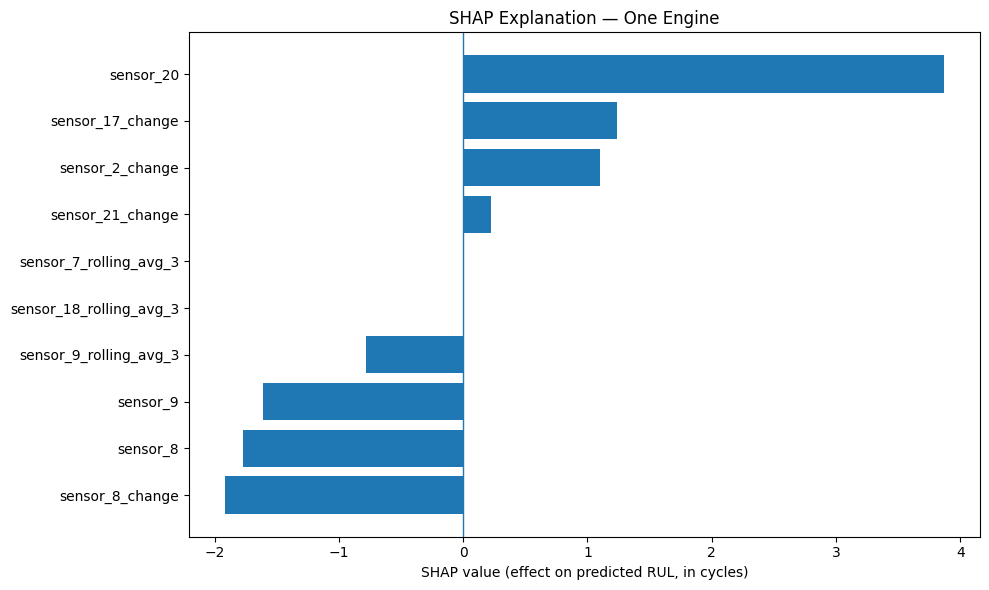

In [0]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Convert SHAP results into a flat array
values = np.array(shap_values).reshape(-1)

# Build a table of feature contributions
shap_results = pd.DataFrame({
    "feature": feature_cols,
    "shap_value": values,
    "absolute_shap": np.abs(values)
}).sort_values("absolute_shap", ascending=False)

# Display the ten most influential features for this engine
display(shap_results.head(10))

# Plot the SHAP contributions
top_features = shap_results.head(10).sort_values("shap_value")

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["shap_value"])
plt.axvline(0, linewidth=1)
plt.xlabel("SHAP value (effect on predicted RUL, in cycles)")
plt.title("SHAP Explanation — One Engine")
plt.tight_layout()
plt.show()

In [0]:
# Explain 10 engines using the existing SHAP explainer
engines_to_explain = shap_sample.iloc[10:20].to_numpy()

shap_values_10 = explainer.shap_values(
    engines_to_explain,
    nsamples=20
)

print("SHAP calculation completed.")
print("SHAP values shape:", np.array(shap_values_10).shape)

  0%|          | 0/10 [00:00<?, ?it/s]

/databricks/python/lib/python3.12/site-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 2 iterations, i.e. alpha=2.633e-01, with an active set of 2 regressors, and the smallest cholesky pivot element being 4.215e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(
/databricks/python/lib/python3.12/site-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 5 iterations, i.e. alpha=1.456e-01, with an active set of 5 regressors, and the smallest cholesky pivot element being 4.215e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(
/databricks/python/lib/python3.12/site-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 6 iterations, i.e. alpha=1.304e-01, with an active set of 6 regressors, and the smallest choles

SHAP calculation completed.
SHAP values shape: (10, 66)


/databricks/python/lib/python3.12/site-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 4 iterations, i.e. alpha=1.557e-01, with an active set of 4 regressors, and the smallest cholesky pivot element being 2.220e-16. Reduce max_iter or increase eps parameters.
  warnings.warn(
/databricks/python/lib/python3.12/site-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 6 iterations, i.e. alpha=1.278e-01, with an active set of 6 regressors, and the smallest cholesky pivot element being 2.220e-16. Reduce max_iter or increase eps parameters.
  warnings.warn(
/databricks/python/lib/python3.12/site-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 8 iterations, i.e. alpha=7.417e-02, with an active set of 8 regressors, and the smallest choles

feature,mean_absolute_shap
sensor_4_rolling_avg_3,0.874786935691626
sensor_17_rolling_avg_3,0.7141223132847768
sensor_4,0.6843518198632753
sensor_12,0.680714595545822
sensor_14,0.5371072462104347
op_setting_1,0.45060871249128354
sensor_8,0.38687101038835564
sensor_13,0.3190739781649894
sensor_12_rolling_avg_3,0.28388751794713424
sensor_3_rolling_avg_3,0.26936914792089833


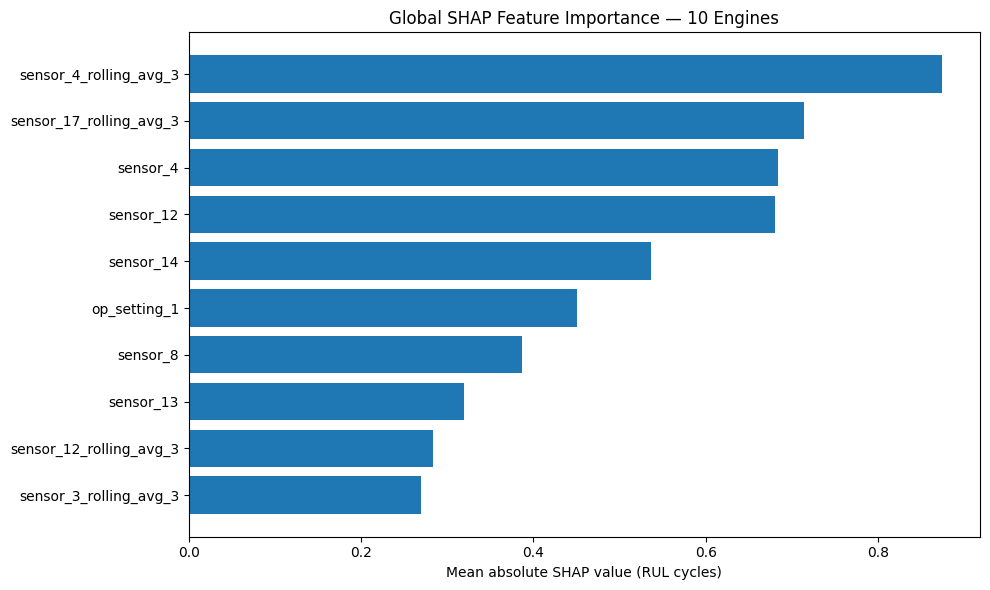

In [0]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Calculate average absolute SHAP contribution
shap_array = np.array(shap_values_10).reshape(10, 66)

global_shap = pd.DataFrame({
    "feature": feature_cols,
    "mean_absolute_shap": np.mean(np.abs(shap_array), axis=0)
}).sort_values("mean_absolute_shap", ascending=False)

# Display top 10 features
display(global_shap.head(10))

# Plot feature importance
top_features = global_shap.head(10).sort_values("mean_absolute_shap")

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["feature"],
    top_features["mean_absolute_shap"]
)
plt.xlabel("Mean absolute SHAP value (RUL cycles)")
plt.title("Global SHAP Feature Importance — 10 Engines")
plt.tight_layout()
plt.show()

In [0]:
shap_global_spark = spark.createDataFrame(global_shap)

shap_global_spark.write \
    .format("delta") \
    .mode("overwrite") \
    .saveAsTable(
        "workspace.predictive_maintenance_rul.shap_feature_importance"
    )

print("SHAP feature importance table saved successfully.")

SHAP feature importance table saved successfully.


In [0]:
display(
    spark.table(
        "workspace.predictive_maintenance_rul.shap_feature_importance"
    ).limit(10)
)

feature,mean_absolute_shap
sensor_4_rolling_avg_3,0.874786935691626
sensor_17_rolling_avg_3,0.7141223132847768
sensor_4,0.6843518198632753
sensor_12,0.680714595545822
sensor_14,0.5371072462104347
op_setting_1,0.45060871249128354
sensor_8,0.38687101038835564
sensor_13,0.3190739781649894
sensor_12_rolling_avg_3,0.28388751794713424
sensor_3_rolling_avg_3,0.26936914792089833


In [0]:
shap_global_spark = spark.createDataFrame(global_shap)

shap_global_spark.write \
    .format("delta") \
    .mode("overwrite") \
    .saveAsTable(
        "workspace.predictive_maintenance_rul.shap_feature_importance"
    )

print("SHAP results saved successfully.")

SHAP results saved successfully.


In [0]:
display(
    spark.table(
        "workspace.predictive_maintenance_rul.shap_feature_importance"
    ).orderBy("mean_absolute_shap", ascending=False)
)

feature,mean_absolute_shap
sensor_4_rolling_avg_3,0.874786935691626
sensor_17_rolling_avg_3,0.7141223132847768
sensor_4,0.6843518198632753
sensor_12,0.680714595545822
sensor_14,0.5371072462104347
op_setting_1,0.45060871249128354
sensor_8,0.38687101038835564
sensor_13,0.3190739781649894
sensor_12_rolling_avg_3,0.28388751794713424
sensor_3_rolling_avg_3,0.26936914792089833


In [0]:
from pyspark.sql import functions as F

# Calculate absolute validation errors
validation_predictions = rul_model.transform(validation_df)

validation_errors = validation_predictions.withColumn(
    "absolute_error",
    F.abs(F.col("RUL") - F.col("prediction"))
)

# Estimate the 90th percentile of absolute error
error_90 = validation_errors.approxQuantile(
    "absolute_error",
    [0.90],
    0.01
)[0]

print(f"90th-percentile validation absolute error: {error_90:.2f} RUL cycles")

90th-percentile validation absolute error: 80.76 RUL cycles


In [0]:
from pyspark.sql import functions as F

error_margin = float(error_90)

uncertainty_df = (
    spark.table("workspace.predictive_maintenance_rul.test_evaluation")
    .withColumn(
        "lower_RUL_estimate",
        F.greatest(
            F.col("predicted_RUL") - F.lit(error_margin),
            F.lit(0.0)
        )
    )
    .withColumn(
        "upper_RUL_estimate",
        F.col("predicted_RUL") + F.lit(error_margin)
    )
    .withColumn(
        "uncertainty_margin_cycles",
        F.lit(error_margin)
    )
)

display(
    uncertainty_df.select(
        "unit_number",
        "predicted_RUL",
        "lower_RUL_estimate",
        "upper_RUL_estimate",
        "uncertainty_margin_cycles"
    ).orderBy("unit_number")
)

unit_number,predicted_RUL,lower_RUL_estimate,upper_RUL_estimate,uncertainty_margin_cycles
1.0,150.73974735588104,69.98073915484974,231.49875555691233,80.75900820103129
2.0,141.24084840175277,60.48184020072148,221.99985660278406,80.75900820103129
3.0,57.39489663217542,0.0,138.1539048332067,80.75900820103129
4.0,108.70212708925236,27.943118888221065,189.46113529028366,80.75900820103129
5.0,116.70589749508645,35.946889294055154,197.46490569611774,80.75900820103129
6.0,137.8292192016432,57.07021100061192,218.5882274026745,80.75900820103129
7.0,112.79117414120427,32.03216594017297,193.55018234223556,80.75900820103129
8.0,119.3888359501291,38.629827749097814,200.1478441511604,80.75900820103129
9.0,136.8817435604274,56.1227353593961,217.6407517614587,80.75900820103129
10.0,128.99967283729856,48.24066463626727,209.75868103832985,80.75900820103129


In [0]:
uncertainty_df.write \
    .format("delta") \
    .mode("overwrite") \
    .saveAsTable(
        "workspace.predictive_maintenance_rul.rul_uncertainty"
    )

print("RUL uncertainty table saved successfully.")

RUL uncertainty table saved successfully.


In [0]:
from pyspark.sql import functions as F

alert_threshold = 30

alert_df = (
    spark.table("workspace.predictive_maintenance_rul.test_evaluation")
    .withColumn(
        "predicted_alert",
        F.col("predicted_RUL") <= alert_threshold
    )
    .withColumn(
        "actual_alert",
        F.col("RUL") <= alert_threshold
    )
)

confusion_counts = alert_df.agg(
    F.sum(
        F.when(
            F.col("predicted_alert") & F.col("actual_alert"), 1
        ).otherwise(0)
    ).alias("true_positives"),
    F.sum(
        F.when(
            F.col("predicted_alert") & ~F.col("actual_alert"), 1
        ).otherwise(0)
    ).alias("false_positives"),
    F.sum(
        F.when(
            ~F.col("predicted_alert") & F.col("actual_alert"), 1
        ).otherwise(0)
    ).alias("false_negatives"),
    F.sum(
        F.when(
            ~F.col("predicted_alert") & ~F.col("actual_alert"), 1
        ).otherwise(0)
    ).alias("true_negatives")
)

display(confusion_counts)

true_positives,false_positives,false_negatives,true_negatives
17,1,8,74


In [0]:
alert_df.write \
    .format("delta") \
    .mode("overwrite") \
    .saveAsTable(
        "workspace.predictive_maintenance_rul.maintenance_alert_evaluation"
    )

print("Maintenance alert evaluation saved successfully.")

Maintenance alert evaluation saved successfully.


In [0]:
display(
    spark.sql("""
        SHOW TABLES IN workspace.predictive_maintenance_rul
    """)
)

database,tableName,isTemporary
predictive_maintenance_rul,maintenance_alert_evaluation,false
predictive_maintenance_rul,rul_uncertainty,false
predictive_maintenance_rul,shap_feature_importance,false
predictive_maintenance_rul,test_evaluation,false
predictive_maintenance_rul,test_features,false
predictive_maintenance_rul,test_raw,false
predictive_maintenance_rul,test_rul_labels,false
predictive_maintenance_rul,train_features,false
predictive_maintenance_rul,train_labeled,false


In [0]:
spark.sql("""
    DESCRIBE TABLE workspace.predictive_maintenance_rul.train_features
""").show(100, truncate=False)

+-----------------------+---------+-------+
|col_name               |data_type|comment|
+-----------------------+---------+-------+
|unit_number            |double   |NULL   |
|cycle                  |double   |NULL   |
|op_setting_1           |double   |NULL   |
|op_setting_2           |double   |NULL   |
|op_setting_3           |double   |NULL   |
|sensor_1               |double   |NULL   |
|sensor_2               |double   |NULL   |
|sensor_3               |double   |NULL   |
|sensor_4               |double   |NULL   |
|sensor_5               |double   |NULL   |
|sensor_6               |double   |NULL   |
|sensor_7               |double   |NULL   |
|sensor_8               |double   |NULL   |
|sensor_9               |double   |NULL   |
|sensor_10              |double   |NULL   |
|sensor_11              |double   |NULL   |
|sensor_12              |double   |NULL   |
|sensor_13              |double   |NULL   |
|sensor_14              |double   |NULL   |
|sensor_15              |double 

In [0]:
try:
    import databricks.feature_engineering
    print("Feature Engineering API is available")
except ImportError:
    print("Feature Engineering API is not available in this environment")

Feature Engineering API is not available in this environment


In [0]:
%pip install databricks-feature-engineering

Looking in indexes: [REDACTED]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 45.1 MB/s  0:00:00
  Attempting uninstall: certifi
    Found existing installation: certifi 2025.11.12
    Not uninstalling certifi at /databricks/python3/lib/python3.12/site-packages, outside environment /local_disk0/.ephemeral_nfs/envs/pythonEnv-2dc444ed-a458-4983-b879-ad4030b83dc5
    Can't uninstall 'certifi'. No files were found to uninstall.
  Attempting uninstall: databricks-sdk
    Found existing installation: databricks-sdk 0.122.0
    Not uninstalling databricks-sdk at /databricks/python3/lib/python3.12/site-packages, outside environment /local_disk0/.ephemeral_nfs/envs/pythonEnv-2dc444ed-a458-4983-b879-ad4030b83dc5
    Can't uninstall 'databricks-sdk'. No files were found to uninstall.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [databricks-feature-engineering]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
dbutils.library.restartPython()

In [0]:
from databricks.feature_engineering import FeatureEngineeringClient

fe = FeatureEngineeringClient()
print("Feature Engineering client initialized successfully")

Feature Engineering client initialized successfully


In [0]:
spark.sql("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT unit_number, cycle) AS unique_engine_cycles,
        COUNT(*) - COUNT(DISTINCT unit_number, cycle) AS duplicate_keys
    FROM workspace.predictive_maintenance_rul.train_features
""").show()

+----------+--------------------+--------------+
|total_rows|unique_engine_cycles|duplicate_keys|
+----------+--------------------+--------------+
|     20631|               20631|             0|
+----------+--------------------+--------------+



In [0]:
spark.sql("""
    SHOW CREATE TABLE workspace.predictive_maintenance_rul.train_features
""").show(truncate=False)

+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [0]:
import inspect

print(inspect.signature(fe.create_table))

(*, name: str, primary_keys: Union[str, List[str]], df: Optional[pyspark.sql.dataframe.DataFrame] = None, timeseries_column: Optional[str] = None, partition_columns: Union[str, List[str], NoneType] = None, schema: Optional[pyspark.sql.types.StructType] = None, description: Optional[str] = None, tags: Optional[Dict[str, str]] = None, **kwargs) -> databricks.ml_features.entities.feature_table.FeatureTable


In [0]:
table_name = "workspace.predictive_maintenance_rul.train_feature_store"

print("Table exists:", spark.catalog.tableExists(table_name))

Table exists: False


In [0]:
from pyspark.sql import functions as F

train_features_df = (
    spark.table("workspace.predictive_maintenance_rul.train_features")
    .withColumn("unit_number", F.col("unit_number").cast("long"))
    .withColumn("cycle", F.col("cycle").cast("long"))
)

train_features_df.select("unit_number", "cycle").printSchema()

root
 |-- unit_number: long (nullable = true)
 |-- cycle: long (nullable = true)



In [0]:
table_name = "workspace.predictive_maintenance_rul.train_feature_store"

print("Table exists:", spark.catalog.tableExists(table_name))

if spark.catalog.tableExists(table_name):
    print("Row count:", spark.table(table_name).count())
    spark.table(table_name).printSchema()

Table exists: False


In [0]:
spark.sql("""
    SHOW TABLES IN workspace.predictive_maintenance_rul
""").show(truncate=False)

+--------------------------+----------------------------+-----------+
|database                  |tableName                   |isTemporary|
+--------------------------+----------------------------+-----------+
|predictive_maintenance_rul|maintenance_alert_evaluation|false      |
|predictive_maintenance_rul|rul_uncertainty             |false      |
|predictive_maintenance_rul|shap_feature_importance     |false      |
|predictive_maintenance_rul|test_evaluation             |false      |
|predictive_maintenance_rul|test_features               |false      |
|predictive_maintenance_rul|test_raw                    |false      |
|predictive_maintenance_rul|test_rul_labels             |false      |
|predictive_maintenance_rul|train_features              |false      |
|predictive_maintenance_rul|train_labeled               |false      |
+--------------------------+----------------------------+-----------+



In [0]:
import databricks.feature_engineering
from databricks.feature_engineering import FeatureEngineeringClient

print("Feature Engineering package version:")
print(getattr(databricks.feature_engineering, "__version__", "Version not exposed"))

print("\ncreate_table method:")
help(FeatureEngineeringClient.create_table)

Feature Engineering package version:
Version not exposed

create_table method:
Help on function create_table in module databricks.feature_engineering.client:

create_table(self, *, name: str, primary_keys: Union[str, List[str]], df: Optional[pyspark.sql.dataframe.DataFrame] = None, timeseries_column: Optional[str] = None, partition_columns: Union[str, List[str], NoneType] = None, schema: Optional[pyspark.sql.types.StructType] = None, description: Optional[str] = None, tags: Optional[Dict[str, str]] = None, **kwargs) -> databricks.ml_features.entities.feature_table.FeatureTable
    Create and return a feature table with the given name and primary keys.

    The returned feature table has the given name and primary keys.
    Uses the provided ``schema`` or the inferred schema
    of the provided ``df``. If ``df`` is provided, this data will be saved in
    a Delta table. Supported data types for features are: ``IntegerType``, ``LongType``,
    ``FloatType``, ``DoubleType``, ``StringType`

In [0]:
print("Catalog and schema:")
spark.sql("SELECT current_catalog(), current_schema()").show(truncate=False)

print("Schema access:")
spark.sql("""
    DESCRIBE SCHEMA workspace.predictive_maintenance_rul
""").show(truncate=False)

print("Source table row count:")
print(
    spark.table(
        "workspace.predictive_maintenance_rul.train_features"
    ).count()
)

Catalog and schema:
+-----------------+----------------+
|current_catalog()|current_schema()|
+-----------------+----------------+
|workspace        |default         |
+-----------------+----------------+

Schema access:
+-------------------------+---------------------------+
|database_description_item|database_description_value |
+-------------------------+---------------------------+
|Catalog Name             |workspace                  |
|Namespace Name           |predictive_maintenance_rul |
|Comment                  |                           |
|Location                 |                           |
|Owner                    |shravyayadavgolla@gmail.com|
+-------------------------+---------------------------+

Source table row count:
20631


In [0]:
from databricks.feature_engineering import FeatureEngineeringClient
from pyspark.sql import functions as F

fe = FeatureEngineeringClient()

train_features_df = (
    spark.table("workspace.predictive_maintenance_rul.train_features")
    .withColumn("unit_number", F.col("unit_number").cast("long"))
    .withColumn("cycle", F.col("cycle").cast("long"))
)

feature_table = fe.create_table(
    name="workspace.predictive_maintenance_rul.train_feature_store",
    primary_keys=["unit_number", "cycle"],
    df=train_features_df,
    description="NASA C-MAPSS FD001 training features for predictive maintenance"
)

print("Feature table creation call completed.")
print("Returned table:", feature_table)

2026/10/24 14:56:55 INFO databricks.ml_features._compute_client._compute_client: Setting columns ['unit_number', 'cycle'] of table 'workspace.predictive_maintenance_rul.train_feature_store' to NOT NULL.
2026/10/24 14:56:57 INFO databricks.ml_features._compute_client._compute_client: Setting Primary Keys constraint ['unit_number', 'cycle'] on table 'workspace.predictive_maintenance_rul.train_feature_store'.
2026/10/24 14:57:04 INFO databricks.ml_features._compute_client._compute_client: Created feature table 'workspace.predictive_maintenance_rul.train_feature_store'.


Feature table creation call completed.
Returned table: <FeatureTable: name='workspace.predictive_maintenance_rul.train_feature_store', table_id='c63fcf42-8436-462d-a839-17996433fd03', description='NASA C-MAPSS FD001 training features for predictive maintenance', primary_keys=['unit_number', 'cycle'], partition_columns=[], features=['unit_number',
 'cycle',
 'op_setting_1',
 'op_setting_2',
 'op_setting_3',
 'sensor_1',
 'sensor_2',
 'sensor_3',
 'sensor_4',
 'sensor_5',
 'sensor_6',
 'sensor_7',
 'sensor_8',
 'sensor_9',
 'sensor_10',
 'sensor_11',
 'sensor_12',
 'sensor_13',
 'sensor_14',
 'sensor_15',
 'sensor_16',
 'sensor_17',
 'sensor_18',
 'sensor_19',
 'sensor_20',
 'sensor_21',
 'max_cycle',
 'RUL',
 'sensor_1_rolling_avg_3',
 'sensor_1_change',
 'sensor_2_rolling_avg_3',
 'sensor_2_change',
 'sensor_3_rolling_avg_3',
 'sensor_3_change',
 'sensor_4_rolling_avg_3',
 'sensor_4_change',
 'sensor_5_rolling_avg_3',
 'sensor_5_change',
 'sensor_6_rolling_avg_3',
 'sensor_6_change',
 

In [0]:
table_name = "workspace.predictive_maintenance_rul.train_feature_store"

print("Table exists:", spark.catalog.tableExists(table_name))
print("Row count:", spark.table(table_name).count())

spark.sql(f"""
    DESCRIBE TABLE {table_name}
""").show(10, truncate=False)

Table exists: True
Row count: 20631
+------------+---------+-------+
|col_name    |data_type|comment|
+------------+---------+-------+
|unit_number |bigint   |NULL   |
|cycle       |bigint   |NULL   |
|op_setting_1|double   |NULL   |
|op_setting_2|double   |NULL   |
|op_setting_3|double   |NULL   |
|sensor_1    |double   |NULL   |
|sensor_2    |double   |NULL   |
|sensor_3    |double   |NULL   |
|sensor_4    |double   |NULL   |
|sensor_5    |double   |NULL   |
+------------+---------+-------+
only showing top 10 rows


In [0]:
from pyspark.sql import functions as F

test_features_df = (
    spark.table("workspace.predictive_maintenance_rul.test_features")
    .withColumn("unit_number", F.col("unit_number").cast("long"))
    .withColumn("cycle", F.col("cycle").cast("long"))
)

test_feature_table = fe.create_table(
    name="workspace.predictive_maintenance_rul.test_feature_store",
    primary_keys=["unit_number", "cycle"],
    df=test_features_df,
    description="NASA C-MAPSS FD001 test features for predictive maintenance evaluation"
)

print("Test Feature Store table created successfully.")
print("Rows:", spark.table(
    "workspace.predictive_maintenance_rul.test_feature_store"
).count())

2026/10/24 14:58:11 INFO databricks.ml_features._compute_client._compute_client: Setting columns ['unit_number', 'cycle'] of table 'workspace.predictive_maintenance_rul.test_feature_store' to NOT NULL.
2026/10/24 14:58:15 INFO databricks.ml_features._compute_client._compute_client: Setting Primary Keys constraint ['unit_number', 'cycle'] on table 'workspace.predictive_maintenance_rul.test_feature_store'.
2026/10/24 14:58:23 INFO databricks.ml_features._compute_client._compute_client: Created feature table 'workspace.predictive_maintenance_rul.test_feature_store'.


Test Feature Store table created successfully.
Rows: 13096


In [0]:
for table_name in [
    "workspace.predictive_maintenance_rul.train_feature_store",
    "workspace.predictive_maintenance_rul.test_feature_store"
]:
    print(f"\nTable: {table_name}")
    print("Exists:", spark.catalog.tableExists(table_name))
    print("Rows:", spark.table(table_name).count())

    spark.sql(f"""
        SELECT
            COUNT(*) AS total_rows,
            COUNT(DISTINCT unit_number, cycle) AS unique_keys
        FROM {table_name}
    """).show()


Table: workspace.predictive_maintenance_rul.train_feature_store
Exists: True
Rows: 20631
+----------+-----------+
|total_rows|unique_keys|
+----------+-----------+
|     20631|      20631|
+----------+-----------+


Table: workspace.predictive_maintenance_rul.test_feature_store
Exists: True
Rows: 13096
+----------+-----------+
|total_rows|unique_keys|
+----------+-----------+
|     13096|      13096|
+----------+-----------+



In [0]:
spark.sql("""
    SHOW TABLES IN workspace.predictive_maintenance_rul
""").show(100, truncate=False)

+--------------------------+----------------------------+-----------+
|database                  |tableName                   |isTemporary|
+--------------------------+----------------------------+-----------+
|predictive_maintenance_rul|maintenance_alert_evaluation|false      |
|predictive_maintenance_rul|rul_uncertainty             |false      |
|predictive_maintenance_rul|shap_feature_importance     |false      |
|predictive_maintenance_rul|test_evaluation             |false      |
|predictive_maintenance_rul|test_feature_store          |false      |
|predictive_maintenance_rul|test_features               |false      |
|predictive_maintenance_rul|test_raw                    |false      |
|predictive_maintenance_rul|test_rul_labels             |false      |
|predictive_maintenance_rul|train_feature_store         |false      |
|predictive_maintenance_rul|train_features              |false      |
|predictive_maintenance_rul|train_labeled               |false      |
+-------------------

In [0]:
spark.sql("""
    SELECT
        COUNT(*) AS evaluated_engines,
        ROUND(AVG(absolute_error), 2) AS test_mae_cycles,
        ROUND(SQRT(AVG(absolute_error * absolute_error)), 2)
            AS test_rmse_cycles
    FROM workspace.predictive_maintenance_rul.test_evaluation
""").show(truncate=False)

+-----------------+---------------+----------------+
|evaluated_engines|test_mae_cycles|test_rmse_cycles|
+-----------------+---------------+----------------+
|100              |20.7           |28.37           |
+-----------------+---------------+----------------+



In [0]:
spark.sql("""
    SELECT *
    FROM workspace.predictive_maintenance_rul.maintenance_alert_evaluation
""").show(100, truncate=False)

+-----------+---+------------------+-------------------+---------------+------------+
|unit_number|RUL|predicted_RUL     |absolute_error     |predicted_alert|actual_alert|
+-----------+---+------------------+-------------------+---------------+------------+
|1.0        |112|150.73974735588104|38.739747355881036 |false          |false       |
|2.0        |98 |141.24084840175277|43.24084840175277  |false          |false       |
|3.0        |69 |57.39489663217542 |11.605103367824583 |false          |false       |
|4.0        |82 |108.70212708925236|26.702127089252357 |false          |false       |
|5.0        |91 |116.70589749508645|25.705897495086447 |false          |false       |
|6.0        |93 |137.8292192016432 |44.82921920164321  |false          |false       |
|7.0        |91 |112.79117414120427|21.791174141204266 |false          |false       |
|8.0        |95 |119.3888359501291 |24.388835950129106 |false          |false       |
|9.0        |111|136.8817435604274 |25.881743560427395